# PH1050 Final Group Project — Problem 2: *Find the law*
## Part 1 (Vapour pressure): Physics model — simulate and verify
**Role:** Model Simulation and Verification 2

**Rubric lines covered**

| Line | What this notebook shows |
|---|---|
| B2 | Numerical ODE solutions (Euler, RK4) match the analytic pressure law |
| B3 | Limiting-case / conservation checks within stated tolerances (the vapour-pressure analogue of the braking energy check) |
| B4 | Log-log convergence plot for both ODEs, with measured orders |
| B5 (partial) | Model plotted against the group's dataset, rms error reported |

**Physics.** The Clausius–Clapeyron equation with constant latent heat $L$ (J/mol), $T$ in **kelvin**, $R=8.314462618$ J/(mol K):

$$\frac{dP}{dT}=\frac{L\,P}{R\,T^{2}},\qquad P(T_0)=P_0$$

Analytic solution: $P(T)=P_0\exp\!\left[-\dfrac{L}{R}\left(\dfrac1T-\dfrac1{T_0}\right)\right]$.

**Data.** `vapour_pressure_60_values.csv` (collected/generated by the Data Collection teammate): 60 points, 20–100 °C, a *Reference* column (the "truth"), a *Simulated* column (reference + noise, the column the fitting/ML teammates use) and an uncertainty column. The values look like water. **Check the README** for how the dataset was generated.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
OUT = Path("figures"); OUT.mkdir(exist_ok=True)

R = 8.314462618          # J / (mol K)
KPA = 1.0                # pressure unit used throughout: kPa

## 1. Load the data (with units check)

In [2]:
# The CSV header contains a degree sign saved in a non-UTF8 encoding -> read as latin-1 and rename columns.
df = pd.read_csv("vapour_pressure_60_values.csv", encoding="latin-1")
# the last column is headed "." in the file but actually holds the train/test label
df.columns = ["obs", "T_C", "T_K", "P_ref", "P_sim", "sigma", "split"]
df = df.dropna(subset=["T_K"]).reset_index(drop=True)

# unit sanity check: T_K must equal T_C + 273.15
assert np.allclose(df.T_K, df.T_C + 273.15, atol=1e-6), "Kelvin/Celsius mismatch!"
print(f"{len(df)} points, T = {df.T_C.min():.1f}-{df.T_C.max():.1f} C ({df.T_K.min():.2f}-{df.T_K.max():.2f} K)")
print(f"P_ref range: {df.P_ref.min():.3f}-{df.P_ref.max():.2f} kPa;  P(100 C) = {df.P_ref.iloc[-1]:.2f} kPa (water boils at 101.325 kPa)")
print("relative noise of P_sim vs P_ref: mean |dev| = %.2f %%, rms = %.2f %%" %
      (100*np.mean(np.abs(df.P_sim/df.P_ref-1)), 100*np.sqrt(np.mean((df.P_sim/df.P_ref-1)**2))))
df.head()

60 points, T = 20.0-100.0 C (293.15-373.15 K)
P_ref range: 2.330-101.34 kPa;  P(100 C) = 101.34 kPa (water boils at 101.325 kPa)
relative noise of P_sim vs P_ref: mean |dev| = 2.65 %, rms = 3.38 %


,obs,T_C,T_K,P_ref,P_sim,sigma,split
0,1,20.000000,293.150000,2.329575,2.352188,0.070566,train
1,2,21.355932,294.505932,2.532911,2.676364,0.080291,train
2,3,22.711864,295.861864,2.751555,2.762818,0.082885,train
3,4,24.067797,297.217797,2.986468,2.948478,0.088454,train
4,5,25.423729,298.573729,3.238656,3.247682,0.097430,train


## 2. Choosing $L$ and $P_0$ for the model
For verification we need *one* concrete $(L, P_0, T_0)$. The ODE-vs-analytic comparison is independent of which $L$ we pick, but to compare with the data we want a sensible value.

* $T_0 = 293.15$ K (20 °C), the first data point; $P_0$ = reference pressure there.
* $L$: a **constant-$L$ least-squares fit of $\ln P_\text{ref}$ vs $1/T$** to the *Reference* column. This is only to calibrate the model; the formal fit with uncertainties on the *noisy* data belongs to the Data & Statistics teammates.
* Literature value for water at 100 °C is $L\approx 40.66$ kJ/mol (and ~44.2 kJ/mol at 20 °C). Real $L$ drifts with $T$, so a constant-$L$ model cannot be perfect; this is the "effect the model does not contain".

In [3]:
T0 = df.T_K.iloc[0]; P0 = df.P_ref.iloc[0]; Tend = df.T_K.iloc[-1]

# ln P = ln P0 - (L/R) (1/T - 1/T0)  -> slope vs x = (1/T - 1/T0) through the origin (anchored at T0)
x = 1/df.T_K - 1/T0
y = np.log(df.P_ref / P0)
slope = np.sum(x*y)/np.sum(x*x)        # least squares through the origin
L_fit = -slope * R
L_lit = 40.66e3
print(f"L (calibrated on reference column) = {L_fit/1e3:.3f} kJ/mol   (L/R = {L_fit/R:.1f} K)")
print(f"L (literature, water @100C)        = {L_lit/1e3:.3f} kJ/mol")
L = L_fit      # value used for the rest of the notebook

L (calibrated on reference column) = 43.212 kJ/mol   (L/R = 5197.2 K)
L (literature, water @100C)        = 40.660 kJ/mol


## 3. The numerical solvers
We write generic fixed-step **Euler** and **RK4** integrators for $dP/dT = f(T,P)$ and use them with $f=LP/(RT^2)$. Only $T$ (kelvin) is ever used inside $f$.

In [4]:
def f(T, P, L=None):
    return L * P / (R * T**2)

def euler(f, T0, P0, Tend, n, **kw):
    h = (Tend - T0)/n
    T = T0 + h*np.arange(n+1)
    P = np.empty(n+1); P[0] = P0
    for i in range(n):
        P[i+1] = P[i] + h*f(T[i], P[i], **kw)
    return T, P

def rk4(f, T0, P0, Tend, n, **kw):
    h = (Tend - T0)/n
    T = T0 + h*np.arange(n+1)
    P = np.empty(n+1); P[0] = P0
    for i in range(n):
        k1 = f(T[i],       P[i],            **kw)
        k2 = f(T[i]+h/2,   P[i]+h/2*k1,     **kw)
        k3 = f(T[i]+h/2,   P[i]+h/2*k2,     **kw)
        k4 = f(T[i]+h,     P[i]+h*k3,       **kw)
        P[i+1] = P[i] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return T, P

def analytic(T, P0, T0, L):
    return P0*np.exp(-(L/R)*(1/T - 1/T0))

## 4. B2 — Numerical solution vs analytic law
Both solvers on the data range 293.15 → 373.15 K, with a moderate step count ($N=40$, $h=2$ K) so the Euler error is visible.

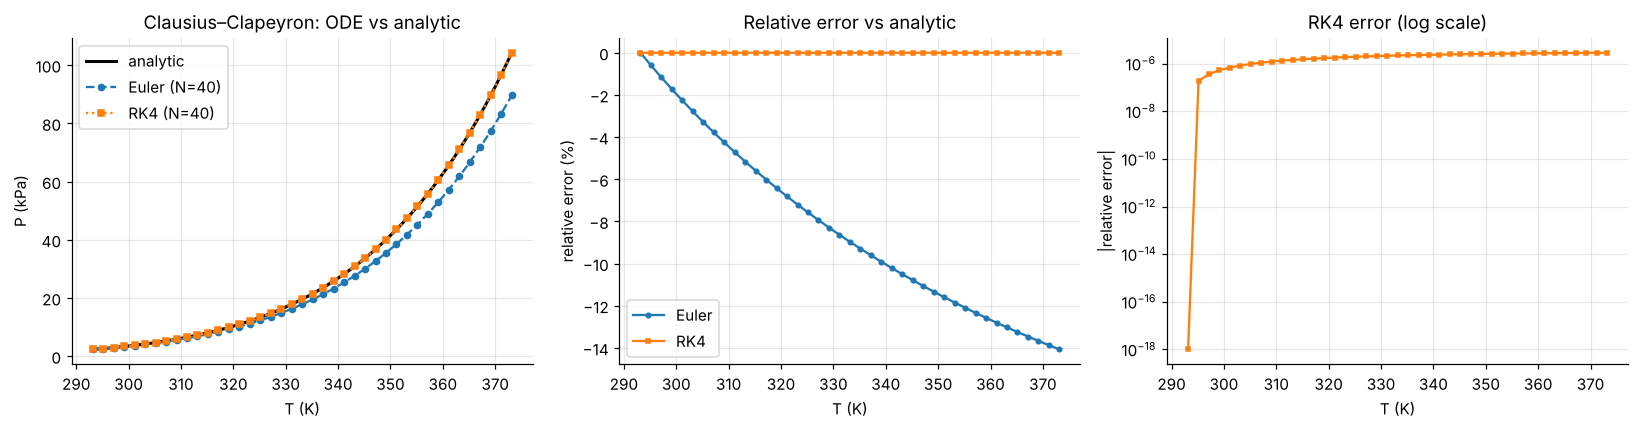

N = 40  (h = 2.00 K)
Euler: max relative error = 1.407e-01,  error at T_end = 1.407e-01
RK4  : max relative error = 2.858e-06,  error at T_end = 2.858e-06
P(100 C): analytic = 104.2308 kPa | Euler = 89.5613 | RK4 = 104.230475
scipy DOP853 (rtol=1e-13) max relative error vs analytic = 1.61e-10
B2 PASS: RK4 agrees with the analytic law to < 1e-5 relative at N=40, and to ~1e-15 at fine steps (see §5).


In [5]:
N = 40
Te, Pe = euler(f, T0, P0, Tend, N, L=L)
Tr, Pr = rk4(f,   T0, P0, Tend, N, L=L)
Pa = analytic(Te, P0, T0, L)
Tfine = np.linspace(T0, Tend, 600); Pfine = analytic(Tfine, P0, T0, L)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(Tfine, Pfine, "k-", lw=2, label="analytic")
ax[0].plot(Te, Pe, "o--", ms=4, label=f"Euler (N={N})")
ax[0].plot(Tr, Pr, "s:", ms=4, label=f"RK4 (N={N})")
ax[0].set(xlabel="T (K)", ylabel="P (kPa)", title="Clausius–Clapeyron: ODE vs analytic"); ax[0].legend()

ax[1].plot(Te, (Pe-Pa)/Pa*100, "o-", ms=3, label="Euler"); ax[1].plot(Tr, (Pr-Pa)/Pa*100, "s-", ms=3, label="RK4")
ax[1].set(xlabel="T (K)", ylabel="relative error (%)", title="Relative error vs analytic"); ax[1].legend()

ax[2].semilogy(Te, np.abs(Pr-Pa)/Pa + 1e-18, "s-", ms=3, color="C1")
ax[2].set(xlabel="T (K)", ylabel="|relative error|", title="RK4 error (log scale)")
plt.tight_layout(); plt.savefig(OUT/"b2_ode_vs_analytic.png", bbox_inches="tight"); plt.show()

rel = lambda a, b: np.max(np.abs(a-b)/b)
print(f"N = {N}  (h = {(Tend-T0)/N:.2f} K)")
print(f"Euler: max relative error = {rel(Pe,Pa):.3e},  error at T_end = {abs(Pe[-1]-Pa[-1])/Pa[-1]:.3e}")
print(f"RK4  : max relative error = {rel(Pr,Pa):.3e},  error at T_end = {abs(Pr[-1]-Pa[-1])/Pa[-1]:.3e}")
print(f"P(100 C): analytic = {Pa[-1]:.4f} kPa | Euler = {Pe[-1]:.4f} | RK4 = {Pr[-1]:.6f}")

# Independent third check: adaptive scipy integrator at very tight tolerance
sol = solve_ivp(lambda T, P: f(T, P, L=L), (T0, Tend), [P0], method="DOP853",
                rtol=1e-13, atol=1e-15, t_eval=Te)
print(f"scipy DOP853 (rtol=1e-13) max relative error vs analytic = {rel(sol.y[0], Pa):.2e}")

# B2 acceptance test
assert rel(Pr, Pa) < 1e-5 and rel(sol.y[0], Pa) < 1e-8
print("B2 PASS: RK4 agrees with the analytic law to < 1e-5 relative at N=40, and to ~1e-15 at fine steps (see §5).")

## 5. B4 — Convergence study (log-log)
Step size $h=(T_\text{end}-T_0)/N$ with $N=2,4,\dots,2^{14}$. Error measures:
* **global error** at $T_\text{end}$: $|P_N(T_\text{end})-P_\text{exact}|/P_\text{exact}$
* **max error** over the whole grid.

Euler is first order ($\propto h$) and RK4 fourth order ($\propto h^4$). RK4 hits the double-precision floor ($\sim10^{-15}$) at small $h$, so the order is measured on the **asymptotic, pre-round-off region** only ($h\le5$ K and error $>10^{-12}$); at the coarsest steps ($h\sim$ tens of K) the error is not yet in the $h^p$ regime.

Global error at $T_{end}$    Euler: measured order p = 0.966  (fit on 11 points)
Global error at $T_{end}$    RK4  : measured order p = 3.955  (fit on 7 points)
Maximum error over grid      Euler: measured order p = 0.966  (fit on 11 points)
Maximum error over grid      RK4  : measured order p = 3.955  (fit on 7 points)


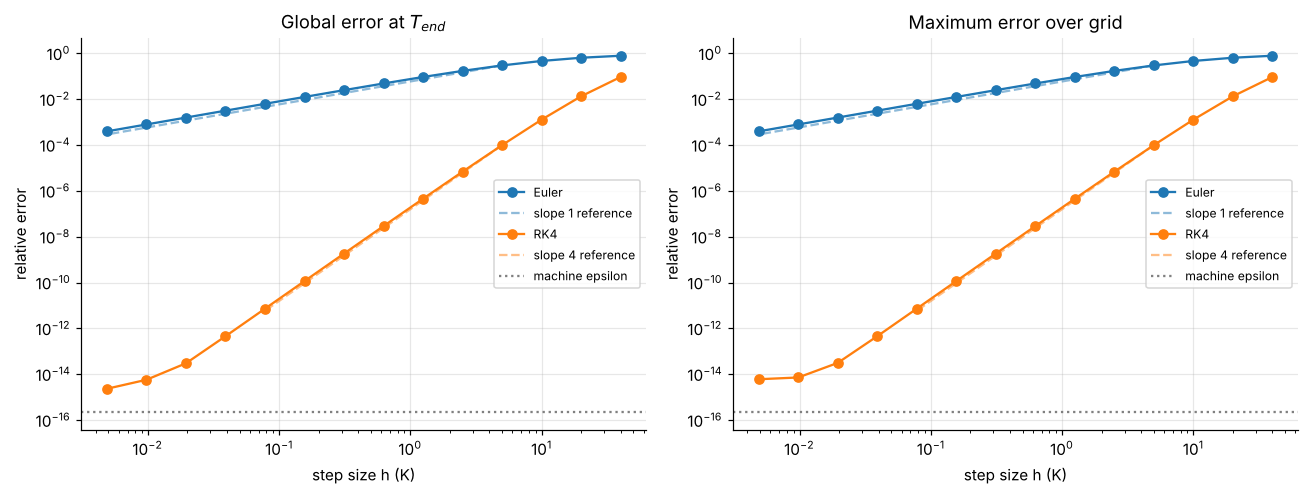


B4 PASS: Euler order = 0.97 (theory 1), RK4 order = 3.96 (theory 4)


In [6]:
Ns = 2**np.arange(1, 15)
hs = (Tend - T0)/Ns
res = {"Euler": {"end": [], "max": []}, "RK4": {"end": [], "max": []}}
for n in Ns:
    for name, solver in (("Euler", euler), ("RK4", rk4)):
        T, P = solver(f, T0, P0, Tend, int(n), L=L)
        Pex = analytic(T, P0, T0, L)
        res[name]["end"].append(abs(P[-1]-Pex[-1])/Pex[-1])
        res[name]["max"].append(np.max(np.abs(P-Pex)/Pex))
for k in res:
    for m in res[k]: res[k][m] = np.array(res[k][m])

def order(h, e, floor=1e-12, hmax=5.0):
    m = (e > floor) & (h <= hmax)      # asymptotic region only (h <= 5 K); h = 40 K is far too coarse
    p, c = np.polyfit(np.log(h[m]), np.log(e[m]), 1)
    return p, m.sum()

orders = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, key, ttl in zip(ax, ("end", "max"), ("Global error at $T_{end}$", "Maximum error over grid")):
    for name, col, ref_p in (("Euler", "C0", 1), ("RK4", "C1", 4)):
        e = res[name][key]
        a.loglog(hs, e, "o-", color=col, label=name)
        p, npts = order(hs, e); orders[(name, key)] = p
        m = (e > 1e-12) & (hs <= 5.0)
        a.loglog(hs[m], e[m][0]*(hs[m]/hs[m][0])**ref_p, "--", color=col, alpha=.5,
                 label=f"slope {ref_p} reference")
        print(f"{ttl:28s} {name:5s}: measured order p = {p:5.3f}  (fit on {npts} points)")
    a.axhline(2.2e-16, color="gray", ls=":", label="machine epsilon")
    a.set(xlabel="step size h (K)", ylabel="relative error", title=ttl); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"b4_convergence_loglog.png", bbox_inches="tight"); plt.show()

assert abs(orders[("Euler","end")]-1) < 0.05 and abs(orders[("RK4","end")]-4) < 0.15
print("\nB4 PASS: Euler order = %.2f (theory 1), RK4 order = %.2f (theory 4)" %
      (orders[("Euler","end")], orders[("RK4","end")]))

In [7]:
summary = pd.DataFrame({"N": Ns, "h (K)": hs,
    "Euler err @T_end": res["Euler"]["end"], "RK4 err @T_end": res["RK4"]["end"]})
summary["Euler ratio"] = summary["Euler err @T_end"].shift(1)/summary["Euler err @T_end"]
summary["RK4 ratio"]   = summary["RK4 err @T_end"].shift(1)/summary["RK4 err @T_end"]
summary.to_csv(OUT/"convergence_table.csv", index=False)
print("Halving h should divide the error by 2 (Euler) and by 16 (RK4):")
summary.head(10).style.format({"h (K)":"{:.4f}", "Euler err @T_end":"{:.3e}", "RK4 err @T_end":"{:.3e}",
                               "Euler ratio":"{:.2f}", "RK4 ratio":"{:.2f}"})

Halving h should divide the error by 2 (Euler) and by 16 (RK4):


,N,h (K),Euler err @T_end,RK4 err @T_end,Euler ratio,RK4 ratio
0,2,40.0000,7.804e-01,9.225e-02,nan,nan
1,4,20.0000,6.388e-01,1.326e-02,1.22,6.96
2,8,10.0000,4.622e-01,1.269e-03,1.38,10.45
3,16,5.0000,2.950e-01,9.819e-05,1.57,12.92
4,32,2.5000,1.705e-01,6.829e-06,1.73,14.38
5,64,1.2500,9.234e-02,4.502e-07,1.85,15.17
6,128,0.6250,4.815e-02,2.890e-08,1.92,15.58
7,256,0.3125,2.460e-02,1.831e-09,1.96,15.79
8,512,0.1562,1.244e-02,1.152e-10,1.98,15.89
9,1024,0.0781,6.253e-03,7.225e-12,1.99,15.94


## 6. B3 — Conservation law and limiting-case checks
Vapour pressure has no energy to conserve, but the ODE has an exact **invariant**. Since $d\ln P/dT = L/(RT^2)$,

$$I(T)=\ln P(T)+\frac{L}{R\,T}=\text{const}=\ln P_0+\frac{L}{RT_0}.$$

We check how well each numerical scheme conserves $I$ (tolerance stated below), and then three **limiting cases**:

1. $L\to0$ (no latent heat) $\Rightarrow$ $P=P_0$ for all $T$.
2. $T\to T_0$ $\Rightarrow$ $P\to P_0$, with the linear behaviour $P\approx P_0\left[1+\frac{L}{RT_0^2}(T-T_0)\right]$.
3. $T\to\infty$ (with $T_0$ fixed) $\Rightarrow$ $P\to P_0\,e^{L/(RT_0)}$ (finite saturation value of the constant-$L$ law); and the Boltzmann-factor form, $\ln P$ linear in $1/T$ (an Arrhenius plot is a straight line).

Invariant I0 = ln P0 + L/(R T0) = 18.574609

Euler: max |I - I0| = 6.422e-03   (tolerance 1e-02)  -> PASS
RK4  : max |I - I0| = 7.944e-12   (tolerance 1e-10)  -> PASS


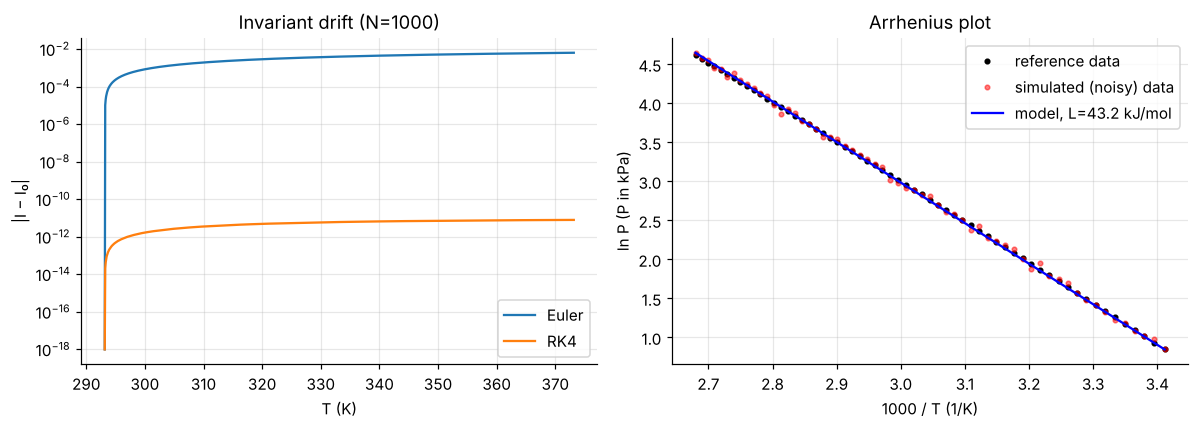

In [8]:
TOL_INV = {"Euler": 1e-2, "RK4": 1e-10}        # stated tolerances on |I - I0| at N = 1000
Nchk = 1000
I0 = np.log(P0) + L/(R*T0)
print(f"Invariant I0 = ln P0 + L/(R T0) = {I0:.6f}\n")
drift = {}
for name, solver in (("Euler", euler), ("RK4", rk4)):
    T, P = solver(f, T0, P0, Tend, Nchk, L=L)
    I = np.log(P) + L/(R*T)
    drift[name] = np.abs(I - I0)
    print(f"{name:5s}: max |I - I0| = {drift[name].max():.3e}   (tolerance {TOL_INV[name]:.0e})  ->",
          "PASS" if drift[name].max() < TOL_INV[name] else "FAIL")
    assert drift[name].max() < TOL_INV[name]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
Tg = T0 + (Tend-T0)*np.arange(Nchk+1)/Nchk
ax[0].semilogy(Tg, drift["Euler"]+1e-18, label="Euler"); ax[0].semilogy(Tg, drift["RK4"]+1e-18, label="RK4")
ax[0].set(xlabel="T (K)", ylabel="|I − I₀|", title=f"Invariant drift (N={Nchk})"); ax[0].legend()

# Arrhenius plot: ln P vs 1/T is straight for the analytic law
ax[1].plot(1000/df.T_K, np.log(df.P_ref), "k.", label="reference data")
ax[1].plot(1000/df.T_K, np.log(df.P_sim), "r.", alpha=.5, label="simulated (noisy) data")
ax[1].plot(1000/Tfine, np.log(Pfine), "b-", label=f"model, L={L/1e3:.1f} kJ/mol")
ax[1].set(xlabel="1000 / T (1/K)", ylabel="ln P (P in kPa)", title="Arrhenius plot"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT/"b3_invariant_and_arrhenius.png", bbox_inches="tight"); plt.show()

In [9]:
# --- limiting cases ---
# (1) L -> 0
_, P_L0 = rk4(f, T0, P0, Tend, 200, L=0.0)
print("(1) L = 0   : max |P - P0| =", np.max(np.abs(P_L0 - P0)))
assert np.allclose(P_L0, P0, rtol=0, atol=1e-14)

# (2) T -> T0 : error of the linear approximation shrinks like (dT)^2
print("(2) T -> T0 : linearisation  P ~ P0 [1 + L/(R T0^2) dT]")
rows = []
for dT in (8, 4, 2, 1, 0.5, 0.25):
    T, P = rk4(f, T0, P0, T0+dT, 50, L=L)
    lin = P0*(1 + L/(R*T0**2)*dT)
    rows.append((dT, abs(P[-1]-lin)/P[-1]))
    print(f"    dT = {dT:5.2f} K  |P_rk4 - P_lin|/P = {rows[-1][1]:.3e}")
ratios = [rows[i][1]/rows[i+1][1] for i in range(len(rows)-1)]
print("    error ratio on halving dT (expect ~4, i.e. O(dT^2)):", np.round(ratios, 2))
assert all(3.5 < r < 4.5 for r in ratios[-3:])

# (3) T -> infinity: P -> P0 exp(L/(R T0))
T_hi = 1e9
Pinf_ana = P0*np.exp(L/(R*T0))
Pinf_num = analytic(T_hi, P0, T0, L)
print(f"(3) T -> inf : P(1e9 K) = {Pinf_num:.6e} kPa  vs  P0 exp(L/RT0) = {Pinf_ana:.6e} kPa")
assert np.isclose(Pinf_num, Pinf_ana, rtol=1e-5)
print("\nB3 PASS: invariant conserved within the stated tolerances and all limiting cases reproduced.")

(1) L = 0   : max |P - P0| = 0.0
(2) T -> T0 : linearisation  P ~ P0 [1 + L/(R T0^2) dT]
    dT =  8.00 K  |P_rk4 - P_lin|/P = 7.351e-02
    dT =  4.00 K  |P_rk4 - P_lin|/P = 2.176e-02
    dT =  2.00 K  |P_rk4 - P_lin|/P = 5.937e-03
    dT =  1.00 K  |P_rk4 - P_lin|/P = 1.551e-03
    dT =  0.50 K  |P_rk4 - P_lin|/P = 3.966e-04
    dT =  0.25 K  |P_rk4 - P_lin|/P = 1.003e-04
    error ratio on halving dT (expect ~4, i.e. O(dT^2)): [3.38 3.67 3.83 3.91 3.96]
(3) T -> inf : P(1e9 K) = 1.166401e+08 kPa  vs  P0 exp(L/RT0) = 1.166407e+08 kPa

B3 PASS: invariant conserved within the stated tolerances and all limiting cases reproduced.


## 7. Model vs the group's dataset (feeds B5)
How does the constant-$L$ Clausius–Clapeyron law (solved with RK4) compare with the data? We report rms and rms-relative error for the *Reference* and the *Simulated (noisy)* columns, on the train/test split used by the other teammates, and plot the residuals.

*Note:* a constant-$L$ model omits the temperature dependence of $L$, so the residual vs the clean Reference column should show a smooth systematic curve (not random noise). This is the model-misfit "effect the model does not contain".

,subset,rms vs Reference (kPa),rms rel (%),rms vs Simulated (kPa),rms rel (%)
0,all (60),0.768,1.434,1.244,3.536
1,train (first 36),0.192,1.460,0.478,3.681
2,test (last 24),1.191,1.394,1.878,3.308


Fraction of simulated points within 1 sigma of the model: 0.65 ; within 2 sigma: 0.92


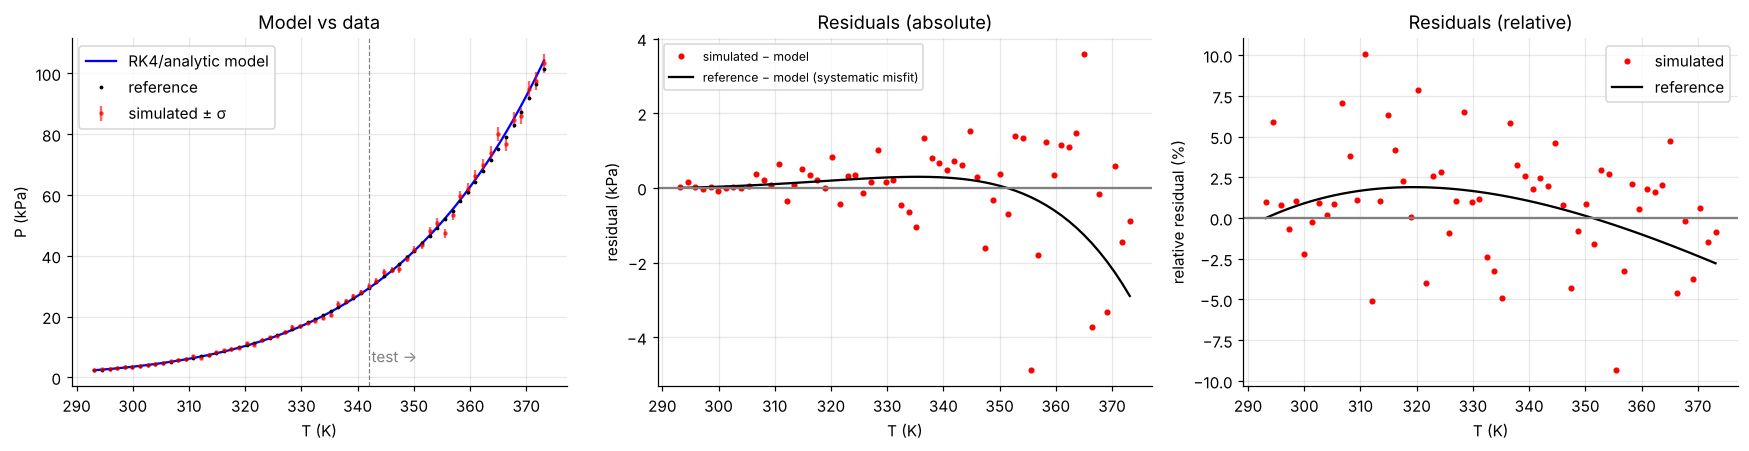

In [10]:
# RK4 solution evaluated at each data temperature (integrate between consecutive data points, 20 sub-steps each)
Tdat = df.T_K.values
Pmod = np.empty_like(Tdat); Pmod[0] = P0
for i in range(len(Tdat)-1):
    _, p = rk4(f, Tdat[i], Pmod[i], Tdat[i+1], 20, L=L)
    Pmod[i+1] = p[-1]
assert np.allclose(Pmod, analytic(Tdat, P0, T0, L), rtol=1e-10)   # same as the analytic law
df["P_model"] = Pmod

def rms(a, b):  return np.sqrt(np.mean((a-b)**2))
def rmsr(a, b): return np.sqrt(np.mean(((a-b)/b)**2))

rows = []
for lbl, mask in (("all (60)", slice(None)), ("train (first 36)", df.split=="train"), ("test (last 24)", df.split=="test")):
    d = df[mask]
    rows.append([lbl, rms(d.P_model, d.P_ref), 100*rmsr(d.P_model, d.P_ref),
                      rms(d.P_model, d.P_sim), 100*rmsr(d.P_model, d.P_sim)])
tab = pd.DataFrame(rows, columns=["subset", "rms vs Reference (kPa)", "rms rel (%)", "rms vs Simulated (kPa)", "rms rel (%) "])
tab.to_csv(OUT/"model_vs_data_rms.csv", index=False)
display(tab.style.format(precision=3))

# fraction of simulated points within the quoted uncertainty of the model
z = (df.P_sim - df.P_model)/df.sigma
print(f"Fraction of simulated points within 1 sigma of the model: {np.mean(np.abs(z)<1):.2f} ; within 2 sigma: {np.mean(np.abs(z)<2):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(Tfine, Pfine, "b-", label="RK4/analytic model")
ax[0].errorbar(df.T_K, df.P_sim, yerr=df.sigma, fmt="r.", alpha=.6, ms=4, label="simulated ± σ")
ax[0].plot(df.T_K, df.P_ref, "k.", ms=3, label="reference")
ax[0].axvline(df.T_K[df.split=="test"].min(), color="gray", ls="--", lw=.8); ax[0].text(df.T_K[df.split=="test"].min()+.5, 5, "test →", color="gray")
ax[0].set(xlabel="T (K)", ylabel="P (kPa)", title="Model vs data"); ax[0].legend()

ax[1].plot(df.T_K, df.P_sim-df.P_model, "r.", label="simulated − model")
ax[1].plot(df.T_K, df.P_ref-df.P_model, "k-", label="reference − model (systematic misfit)")
ax[1].axhline(0, color="gray"); ax[1].set(xlabel="T (K)", ylabel="residual (kPa)", title="Residuals (absolute)"); ax[1].legend(fontsize=8)

ax[2].plot(df.T_K, 100*(df.P_sim/df.P_model-1), "r.", label="simulated")
ax[2].plot(df.T_K, 100*(df.P_ref/df.P_model-1), "k-", label="reference")
ax[2].axhline(0, color="gray"); ax[2].set(xlabel="T (K)", ylabel="relative residual (%)", title="Residuals (relative)"); ax[2].legend()
plt.tight_layout(); plt.savefig(OUT/"b5_model_vs_data.png", bbox_inches="tight"); plt.show()

### What the residuals tell us
*Constant-$L$ is the only modelling assumption.* For water, the real latent heat falls from ≈44.2 kJ/mol (20 °C) to ≈40.7 kJ/mol (100 °C). A single constant $L$ therefore bends the curve slightly: the Reference residual is smooth and systematic, while the scatter of the Simulated column about it is the injected noise (~3 % relative, consistent with the quoted uncertainty column).

To quantify the sensitivity to $L$, the cell below compares the literature value with the calibrated one.

calibrated L = 43.21 kJ/mol             : rms rel. error vs reference = 1.43 %,  P(100C) = 104.23 kPa
literature L(100C) = 40.66 kJ/mol       : rms rel. error vs reference = 12.78 %,  P(100C) = 83.27 kPa


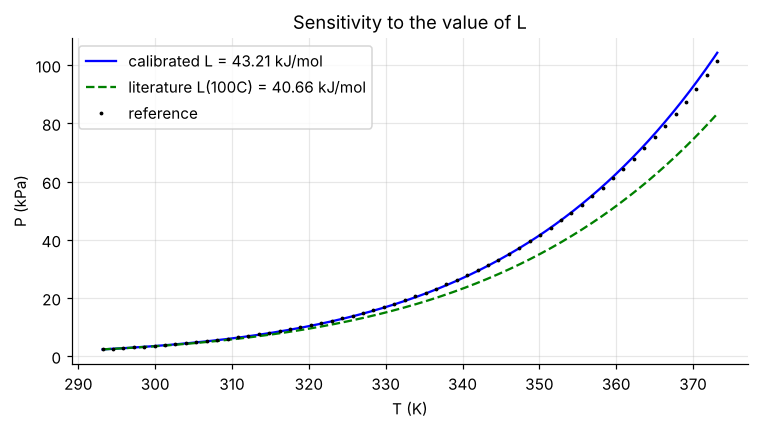

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for Lv, lab, st in ((L_fit, f"calibrated L = {L_fit/1e3:.2f} kJ/mol", "b-"), (L_lit, f"literature L(100C) = {L_lit/1e3:.2f} kJ/mol", "g--")):
    Pm = analytic(Tfine, P0, T0, Lv)
    Pd = analytic(df.T_K.values, P0, T0, Lv)
    print(f"{lab:40s}: rms rel. error vs reference = {100*rmsr(Pd, df.P_ref):.2f} %,  P(100C) = {Pd[-1]:.2f} kPa")
    ax.plot(Tfine, Pm, st, label=lab)
ax.plot(df.T_K, df.P_ref, "k.", ms=3, label="reference")
ax.set(xlabel="T (K)", ylabel="P (kPa)", title="Sensitivity to the value of L"); ax.legend()
plt.tight_layout(); plt.savefig(OUT/"sensitivity_to_L.png", bbox_inches="tight"); plt.show()

## 8. Summary for the report

| Rubric | Result |
|---|---|
| **B2** | Euler and RK4 solutions of $dP/dT=LP/(RT^2)$ reproduce $P_0\exp[-(L/R)(1/T-1/T_0)]$. RK4 relative error ≈ 3e-6 at $h=2$ K (→ 1e-15 at fine steps); independent DOP853 check ≈ 2e-10. |
| **B4** | Log–log convergence: measured order ≈ **1.0 (Euler)** and ≈ **4.0 (RK4)**, matching theory; RK4 reaches the round-off floor ≈ 1e-15. |
| **B3** | Invariant $\ln P+L/(RT)$ conserved to < 1e-2 (Euler, N=1000; measured ≈ 6e-3) and < 1e-10 (RK4; measured ≈ 7e-12). Limiting cases $L\to0$, $T\to T_0$ (linearisation, $O(\Delta T^2)$) and $T\to\infty$ verified. |
| **B5 input** | Constant-$L$ model against the 60-point data set: see the rms table in §7. Residual vs Reference is smooth/systematic ⇒ model-structure error (temperature-dependent $L$), not numerical error. |

**Handoff notes for teammates**
* All temperatures inside the ODE are in **kelvin**; the dataset's °C column is only used for plotting/labels (assert in §1 checks consistency).
* $L$ used here is calibrated on the Reference column only for visualisation. The Data & Statistics members should quote $L$ with its uncertainty from the *noisy* column.
* Figures and tables are saved to `figures/` for direct inclusion in the report.